# Unsupervised Learning: From Zero to Confident
**A Complete Masterclass in Clustering, Dimensionality Reduction, and Anomaly Detection**

Welcome! I am your Senior ML Mentor, and my mission is to take you from knowing nothing about unsupervised machine learning to feeling completely confident building and debugging real algorithms.

Here is my promise to you:
1. **Zero Jargon Without Warning**: Every single concept starts with a 1-sentence summary, a friendly real-life analogy, and a tiny pencil-and-paper calculation before we touch code or math.
2. **Every Symbol Explained**: If you see an equation, every single letter and greek symbol is defined in plain English right next to it.
3. **From Scratch, Then Production**: We will build core algorithms (K-Means, PCA) from raw NumPy matrices first, and then compare against scikit-learn.
4. **Failure Analysis**: We will deliberately break our algorithms so you understand exactly *why* they fail and how to fix them.

---

## Master Glossary
*We will maintain this living dictionary throughout our journey. Every time a new concept appears, it gets added right here.*

| Term | One-Sentence Definition |
| :--- | :--- |
| **Unsupervised Learning** | Finding hidden patterns or groupings in data without any teacher, labels, or target answers. |
| **Sample (or Instance)** | A single individual observation in our dataset (for example, one customer row). |
| **Feature (or Attribute)** | A measurable characteristic of a sample (for example, Age, Annual Income, or Spending Score). |
| **Label (or Target)** | The pre-existing "correct answer" or category assigned to a sample (unsupervised learning has **no labels**!). |
| **Cluster** | A collection of data points that are more similar to each other than to points in other collections. |
| **Distance Metric** | A mathematical ruler that calculates numerical separation (dissimilarity) between two data points. |
| **Euclidean Distance** | The straight-line "as the crow flies" distance between two points in geometry. |
| **Manhattan Distance** | The distance measured along right-angle grid paths, like walking city blocks in Manhattan. |
| **Feature Scaling** | Transforming feature values so all dimensions share a comparable numerical scale and weight. |
| **StandardScaler (Z-Score)** | Scaling data by subtracting the feature's mean and dividing by its standard deviation ($z = \frac{x - \mu}{\sigma}$). |


# Step 1: Unsupervised Learning Foundations
### No Labels, Distance Metrics, and Why Scaling Matters

---

### Concept 1.1: What "No Labels" Means

#### 1. The Idea in ONE Plain Sentence
Unsupervised learning means finding natural groupings or patterns in data when nobody gave you the "correct answers" or category names in advance.

#### 2. Real-Life Analogy
Imagine dumping a huge basket of clean, unlabeled laundry onto your bed. Nobody gave you sticky notes saying "T-shirt", "Socks", or "Jeans". Yet, by looking at texture, color, and size, your hands naturally group the soft white socks together and the thick blue denim jeans together. That is unsupervised learning: grouping by similarity without a teacher.

#### 3. Tiny Example with Real Numbers Worked by Hand
Suppose we observe 4 shoppers with two features: **(Store Visits this Month, Dollars Spent)**:
- Customer A: $(1, 10)$
- Customer B: $(2, 12)$
- Customer C: $(20, 200)$
- Customer D: $(22, 210)$

Notice:
- A and B have visits separated by $|1 - 2| = 1$ and spend separated by $|10 - 12| = 2$. They are practically identical!
- C and D have visits separated by $|20 - 22| = 2$ and spend separated by $|200 - 210| = 10$. They are also very close!
- But A and C are separated by 19 visits and \$190.
Without any supervisor telling us who is a "casual browser" or "VIP shopper", the data naturally falls into two distinct clusters: $\{A, B\}$ and $\{C, D\}$.

#### 4. The Math with EVERY Symbol Explained in Words
In supervised learning, data comes as a pair $(X, y)$, where:
- $X$ is the input data matrix.
- $y$ is the teacher's answer key (e.g., $y=1$ for fraud, $y=0$ for normal).

In **unsupervised learning**, there is **no $y$**!
$$X \in \mathbb{R}^{n \times d}$$
Where:
- $X$ is our data matrix (a table of numbers).
- $\in$ means "is an element of" (our matrix lives in this mathematical space).
- $\mathbb{R}$ stands for Real numbers (numbers like 1.5, -3, 42.0).
- $n$ is the total number of samples (rows, e.g., 200 customers).
- $d$ is the number of features (columns, e.g., Age, Income).
- There is NO target vector $y$. The algorithm must learn entirely from $X$.

#### 5. Code Demonstration
Let us create and inspect a simple unlabelled 2D dataset representing customer visits and spending.


#### What We Are About to Do and Why
We will import NumPy and Matplotlib, create our tiny 4-customer dataset plus a cloud of synthetic shoppers, and plot them with no color labels to experience what "unlabeled data" looks like to an algorithm.


In [1]:
# Step 1.1 Code: Visualizing Unlabeled Customer Data
import numpy as np
import matplotlib.pyplot as plt

# Set random seed so results are 100% reproducible
np.random.seed(42)

# Generate two natural clusters of customers: (Visits, Spend)
group_casual = np.random.normal(loc=[3, 20], scale=[1.0, 5], size=(30, 2))
group_vip = np.random.normal(loc=[25, 220], scale=[3.0, 25], size=(30, 2))

# Combine into a single unlabeled matrix X (no labels y!)
X_raw = np.vstack([group_casual, group_vip])
print(f"Shape of X: {X_raw.shape} (60 customers, 2 features)")


Shape of X: (60, 2) (60 customers, 2 features)


#### What We Just Saw
We created a 2D matrix of shape `(60, 2)` containing 60 customers. Notice that we combined both groups into `X_raw`. There is no `y` vector storing group names. Now let us plot this unlabelled data.


#### What We Are About to Do and Why
We will plot `X_raw` as gray scatter points. Because there are no labels, every point has the exact same color.


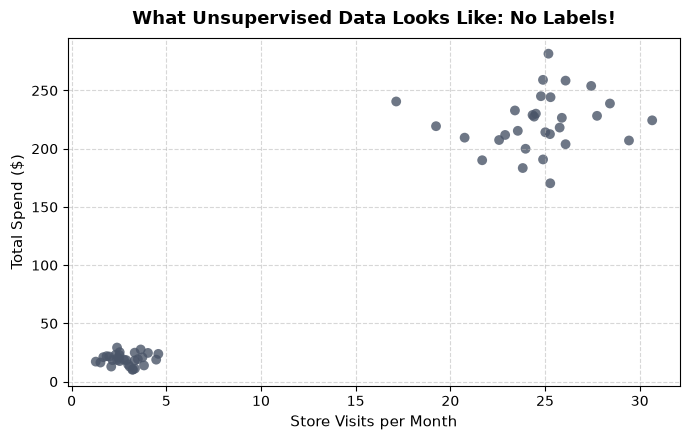

In [2]:
# Step 1.1 Plot: The Unlabeled Customer Cloud
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X_raw[:, 0], X_raw[:, 1], color='#4A5568', s=50, alpha=0.8, edgecolors='none')
ax.set_title("What Unsupervised Data Looks Like: No Labels!", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Store Visits per Month", fontsize=11)
ax.set_ylabel("Total Spend ($)", fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#### How to Read This Plot
- **X-axis**: Store Visits per Month (from ~0 to 30 visits).
- **Y-axis**: Total Spend in dollars (from ~\$10 to \$300).
- **What a good result looks like**: Notice how your human eyes immediately spot two distinct islands of dots without needing colors or labels.
- **What a bad result looks like**: If the data was completely uniform white noise with no structure, clustering would be meaningless.
- **What this tells us**: Even without a single label, the geometric structure of the data reveals two clear groups of customers!

#### 6. One Common Beginner Mistake
Expecting the computer to automatically invent human business names like "VIP Shoppers" or "Casual Browsers". Unsupervised algorithms only output cluster numbers (`0`, `1`, `2`). A human domain expert must inspect the features of each cluster to assign meaningful business names!

#### 7. Quick "Check Yourself" Question
**Question**: If you have a dataset with 500 rows and 10 columns, and you want to predict whether a customer will churn (Yes/No) using historical Churn column data, is this Supervised or Unsupervised learning?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: It is **Supervised Learning**! Because you have a target column ("Churn: Yes/No") that serves as the teacher's answer key ($y$), the algorithm is being guided by known answers. Unsupervised learning is when you do *not* have an answer key and are trying to discover groupings on your own.
</details>

---

### Concept 1.2: Distance Metrics (Euclidean vs. Manhattan)

#### 1. The Idea in ONE Plain Sentence
A distance metric is a mathematical ruler that measures how far apart two data points are, which tells us how similar or different they are.

#### 2. Real-Life Analogy
- **Euclidean Distance**: Imagine an open grassy park. You can walk straight from point A to point B as the crow flies, cutting across the grass.
- **Manhattan Distance**: Imagine downtown Manhattan, New York. You cannot walk through skyscrapers! You have to walk 3 blocks East, then 4 blocks North along the city street grid.

#### 3. Tiny Example with Real Numbers Worked by Hand
Let us take two points:
- Point $p = (2, 3)$
- Point $q = (5, 7)$

First, calculate the coordinate differences:
- $\Delta x = q_1 - p_1 = 5 - 2 = 3$
- $\Delta y = q_2 - p_2 = 7 - 3 = 4$

**Euclidean Distance (Straight Line)**:
$$d_{\text{Euclidean}} = \sqrt{3^2 + 4^2} = \sqrt{9 + 16} = \sqrt{25} = 5.0$$

**Manhattan Distance (City Block)**:
$$d_{\text{Manhattan}} = |3| + |4| = 3 + 4 = 7.0$$

Notice: Manhattan distance ($7.0$) is always greater than or equal to Euclidean distance ($5.0$) because walking around blocks is longer than cutting straight across!

#### 4. The Math with EVERY Symbol Explained in Words

**Euclidean Distance Formula**:
$$d_{\text{Euclidean}}(p, q) = \sqrt{\sum_{i=1}^{d} (p_i - q_i)^2}$$
- $d_{\text{Euclidean}}(p, q)$: The Euclidean distance between vector point $p$ and vector point $q$.
- $\sqrt{\dots}$: The square root function (undoes the squaring to restore original units).
- $\sum_{i=1}^{d}$: The summation symbol. It means "add up the terms for every feature from $i=1$ up to $d$".
- $d$: The number of dimensions (features) in our dataset.
- $p_i$: The value of feature $i$ for point $p$.
- $q_i$: The value of feature $i$ for point $q$.
- $(p_i - q_i)^2$: The squared difference. Squaring prevents positive and negative differences from canceling out and heavily penalizes large gaps.

**Manhattan Distance (L1 Distance) Formula**:
$$d_{\text{Manhattan}}(p, q) = \sum_{i=1}^{d} |p_i - q_i|$$
- $|p_i - q_i|$: The absolute value of the difference (removes negative signs without squaring).
- $\sum_{i=1}^{d}$: Sum of all absolute coordinate differences across all features.


#### What We Are About to Do and Why
We will write pure NumPy functions for both Euclidean and Manhattan distances and test them on our hand-calculated points $p=(2, 3)$ and $q=(5, 7)$ to verify our math.


In [3]:
# Step 1.2 Code: Distance Metrics from Scratch in NumPy
def euclidean_distance(p, q):
    """Calculates straight-line (L2) distance between points p and q."""
    diff = np.array(p) - np.array(q)
    return np.sqrt(np.sum(diff ** 2))

def manhattan_distance(p, q):
    """Calculates grid-based (L1) distance between points p and q."""
    diff = np.array(p) - np.array(q)
    return np.sum(np.abs(diff))

# Test on hand-calculated example
p, q = np.array([2, 3]), np.array([5, 7])
print(f"Euclidean distance: {euclidean_distance(p, q):.2f} (Expected: 5.00)")
print(f"Manhattan distance: {manhattan_distance(p, q):.2f} (Expected: 7.00)")


Euclidean distance: 5.00 (Expected: 5.00)
Manhattan distance: 7.00 (Expected: 7.00)


#### What We Just Saw
Our NumPy functions output `5.00` and `7.00`, perfectly matching our pencil-and-paper calculations. Both functions operate on vectors of any dimension $d$.

#### 6. One Common Beginner Mistake
Using Euclidean distance on very high-dimensional data (e.g. 10,000 text features) without realizing that in high dimensions, the distance between almost all pairs of points becomes nearly identical! This phenomenon is known as the **Curse of Dimensionality** (which we will solve in Step 6 using PCA).

#### 7. Quick "Check Yourself" Question
**Question**: Suppose point A is $(0, 0)$ and point B is $(3, -4)$. What is the Manhattan distance between them?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: $7$!
- $|3 - 0| = 3$
- $|-4 - 0| = |-4| = 4$
- Manhattan Distance = $3 + 4 = 7$.
*(Notice that the Euclidean distance would be $\sqrt{3^2 + (-4)^2} = \sqrt{9 + 16} = 5$.)*
</details>

---

### Concept 1.3: Why Feature Scaling is Mandatory (Demo It Breaking Clusters!)

#### 1. The Idea in ONE Plain Sentence
When features are measured in different units (like Age in tens vs. Salary in hundreds of thousands), the feature with larger numbers completely bullies the distance calculation and destroys your clusters.

#### 2. Real-Life Analogy
Imagine judging a used car contest based on two features:
1. **Price difference** (e.g., \$10,000 difference).
2. **Number of cup holders** (e.g., 2 cup holders difference).

If you feed raw numbers into Euclidean distance, the calculation sees:
$$\sqrt{(10000)^2 + (2)^2} = \sqrt{100,000,000 + 4} = 10,000.0002$$
The cup holder feature was effectively erased! The price completely bulldozed the comparison.

#### 3. Tiny Example with Real Numbers Worked by Hand
Let us look at three customers:
- Customer A: Age = $25$, Income = $\$50,000$
- Customer B: Age = $26$, Income = $\$50,100$
- Customer C: Age = $70$, Income = $\$50,050$

Notice the human reality:
- Customer A and B are young 20-somethings with virtually the same income.
- Customer C is a 70-year-old senior citizen, 45 years older than Customer A!

Now calculate raw Euclidean distance from Customer A:
- **Distance(A, B)**:
  $$\sqrt{(26 - 25)^2 + (50100 - 50000)^2} = \sqrt{1^2 + 100^2} = \sqrt{10001} \approx 100.005$$
- **Distance(A, C)**:
  $$\sqrt{(70 - 25)^2 + (50050 - 50000)^2} = \sqrt{45^2 + 50^2} = \sqrt{2025 + 2500} = \sqrt{4525} \approx 67.27$$

**The Catastrophe**:
Distance(A, C) is $67.27$, while Distance(A, B) is $100.00$!
The raw calculation says Customer A is **closer to a 70-year-old senior than to their 26-year-old peer**, solely because of a tiny \$50 difference in annual income!

#### 4. The Math with EVERY Symbol Explained in Words

**5-Line Math Refresher**:
- **Mean (Average) $\mu$**: Sum of all values divided by count: $\mu = \frac{1}{n}\sum_{i=1}^n x_i$.
- **Variance $\sigma^2$**: Average squared distance from the mean: $\sigma^2 = \frac{1}{n}\sum_{i=1}^n (x_i - \mu)^2$.
- **Standard Deviation $\sigma$**: The square root of variance: $\sigma = \sqrt{\sigma^2}$ (measures spread in original units).

**StandardScaler (Z-Score Normalization)**:
$$z = \frac{x - \mu}{\sigma}$$
Where:
- $z$: The standardized value (how many standard deviations $x$ is from the average).
- $x$: The original raw feature value.
- $\mu$ (mu): The mean (average) of this feature across all samples.
- $\sigma$ (sigma): The standard deviation (spread) of this feature across all samples.

After standard scaling, every feature has:
- Mean $\mu = 0$
- Standard deviation $\sigma = 1$
Now 1 unit of Age carries the exact same mathematical weight as 1 unit of Income!


#### What We Are About to Do and Why
We will create a synthetic dataset of 150 customers with two features: **Age** (years, range 20 to 65) and **Annual Income** (dollars, range \$20,000 to \$120,000). There are 3 natural real-life customer groups.


In [4]:
# Step 1.3 Code: Generating Realistic Customer Age & Income Data
np.random.seed(42)

# Group 1: Young Low-Earners (Age ~25, Income ~$30k)
g1 = np.random.normal(loc=[25, 30000], scale=[3, 4000], size=(50, 2))
# Group 2: Young High-Earners (Age ~28, Income ~$100k)
g2 = np.random.normal(loc=[28, 100000], scale=[3, 5000], size=(50, 2))
# Group 3: Older High-Earners (Age ~58, Income ~$105k)
g3 = np.random.normal(loc=[58, 105000], scale=[4, 6000], size=(50, 2))

# Stack into full dataset
X_demo = np.vstack([g1, g2, g3])
print(f"Generated {len(X_demo)} customers across 3 real groups.")
print(f"Sample customer [Age, Income]: {X_demo[0]}")


Generated 150 customers across 3 real groups.
Sample customer [Age, Income]: [2.64901425e+01 2.94469428e+04]


#### What We Just Saw
We have 150 customers. Notice the scale difference: Age ranges from 20 to 65 (span of ~45), while Income ranges from \$20,000 to \$120,000 (span of ~\$100,000). That is a $2,000\times$ scale mismatch!


#### What We Are About to Do and Why
We will cluster this customer data using K-Means twice:
1. First, on the **raw unscaled data**.
2. Second, on the **StandardScaler standardized data**.
Then we will plot them side by side to see how unscaled data ruins clustering.


In [5]:
# Step 1.3 Code: Clustering Unscaled vs. Scaled Data
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Cluster on Raw Unscaled Data
kmeans_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_unscaled = kmeans_unscaled.fit_predict(X_demo)

# 2. Scale features using StandardScaler
scaler = StandardScaler()
X_demo_scaled = scaler.fit_transform(X_demo)

# 3. Cluster on Properly Scaled Data
kmeans_scaled = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_scaled = kmeans_scaled.fit_predict(X_demo_scaled)

print("Clustering completed for both unscaled and scaled datasets.")


Clustering completed for both unscaled and scaled datasets.


#### What We Just Saw
Both models clustered the 150 customers into 3 groups. Now let us visualize the cluster assignments to see the catastrophic failure of unscaled features.


#### What We Are About to Do and Why
We will plot the two clustering results side-by-side using vibrant distinct colors.


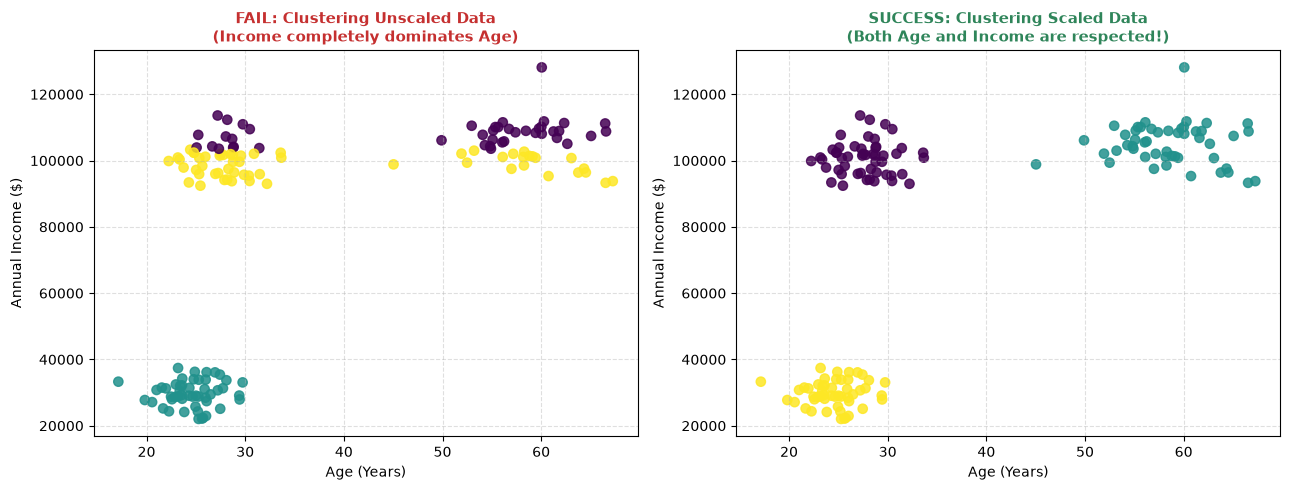

In [6]:
# Step 1.3 Plot: Unscaled vs Scaled Clustering Failure Demo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Unscaled Result
scatter1 = ax1.scatter(X_demo[:, 0], X_demo[:, 1], c=labels_unscaled, cmap='viridis', s=45, alpha=0.85)
ax1.set_title("FAIL: Clustering Unscaled Data\n(Income completely dominates Age)", fontsize=11, fontweight='bold', color='#C53030')
ax1.set_xlabel("Age (Years)", fontsize=10)
ax1.set_ylabel("Annual Income ($)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.4)

# Plot Scaled Result
scatter2 = ax2.scatter(X_demo[:, 0], X_demo[:, 1], c=labels_scaled, cmap='viridis', s=45, alpha=0.85)
ax2.set_title("SUCCESS: Clustering Scaled Data\n(Both Age and Income are respected!)", fontsize=11, fontweight='bold', color='#2F855A')
ax2.set_xlabel("Age (Years)", fontsize=10)
ax2.set_ylabel("Annual Income ($)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


#### How to Read This Plot
- **X-axis**: Age of the customer in years (range 20 to 65).
- **Y-axis**: Annual Income in dollars (range \$20,000 to \$120,000).
- **Left Plot (Unscaled - BAD)**:
  - Look at the top half: Young High-Earners (age ~28) and Older High-Earners (age ~58) got merged into the exact same horizontal clusters!
  - The algorithm cut the data into horizontal strips purely based on income. A 30-year age gap was treated as virtually zero because \$10,000 is numerically larger than 30.
- **Right Plot (Scaled - GOOD)**:
  - The algorithm cleanly recovers all 3 distinct human groups:
    1. Young Low-Earners (bottom left).
    2. Young High-Earners (top left).
    3. Older High-Earners (top right).
- **What this tells us**: Scaling is not an optional "nice-to-have"; without scaling, distance-based unsupervised learning is broken!

#### 6. One Common Beginner Mistake
Fitting the scaler on the whole dataset including future test data (causing data leakage in evaluation), or forgetting to use `scaler.transform()` on new customer records when making predictions in production.

#### 7. Quick "Check Yourself" Question
**Question**: If feature A is measured in millimeters (range 1 to 5000) and feature B is measured in meters (range 0.001 to 5), what will happen if you run K-Means without scaling?

<details>
<summary><b>Click to reveal answer</b></summary>

**Answer**: Feature A will completely dominate the distance calculations because its numerical values are $1000\times$ larger, even though physical distances represented by both features might be identical! Scaling brings both features to equal footing.
</details>

---

### Step 1 Summary
- **Recap in 3 bullets**:
  1. Unsupervised learning finds natural clusters and structures in data without pre-existing labels or teacher answers.
  2. Distance metrics (Euclidean straight-line, Manhattan city-grid) measure sample similarity based on coordinate gaps.
  3. Feature scaling (like StandardScaler) is mandatory because distance metrics treat numerical magnitudes equally regardless of units.
- **If you remember only one thing**:
  *Distance metrics treat 1 dollar the same as 1 year of age; always scale your features before clustering!*
